# Genetic Algorithm (GA)


### Learning Goals
By the end of this lab, you should be able to:
- Define a Genetic Algorithm and explain its inspiration from natural evolution.
- Represent candidate solutions as binary chromosomes.
- Implement initialization, fitness evaluation, selection, crossover, and mutation.
- Build a complete Genetic Algorithm loop and observe how the population improves.

### Problem statement
Use a Genetic Algorithm to find a value of \(x\) between 0 and 31 that maximizes:

\[
f(x) = x^2
\]

Represent each candidate solution as a **5-bit binary chromosome**. For example, `00101` represents decimal 5, so its fitness is \(5^2=25\). The maximum possible value is \(31^2=961\).

## 1. What is a Genetic Algorithm?

A **Genetic Algorithm (GA)** is a population-based optimization technique inspired by natural selection and evolution. It starts with several candidate solutions and repeatedly improves them using operators inspired by genetics.

Each candidate solution is called an **individual**. In this lab, an individual is a 5-bit binary string called a **chromosome**. The fitness function tells us how good that candidate solution is.

### Main steps of a Genetic Algorithm

1. **Initialize population:** Generate a set of random chromosomes.
2. **Evaluate fitness:** Decode each chromosome and calculate its fitness using \(f(x)=x^2\).
3. **Selection:** Choose parents, giving better solutions a greater chance of being selected.
4. **Crossover:** Combine parts of two parents to create offspring.
5. **Mutation:** Randomly flip bits to maintain diversity and explore new solutions.
6. **Replacement / next generation:** Form the next population, optionally preserving the best individual using elitism.
7. **Termination:** Repeat until the generation limit is reached or a satisfactory solution is found.

**Important:** A GA is stochastic (randomized). Different runs may follow different paths, so the exact generations can vary.

## 2. Pseudocode of the complete Genetic Algorithm

```text
BEGIN
    Define chromosome length, population size, mutation rate, and generations

    Create an initial population of random chromosomes

    #00101, 11000, 01110, 00011, 10100, 11100

    Evaluate the fitness of every chromosome

    FOR each generation:
        Preserve the best chromosome (elitism)

        WHILE the next population is not full:
            Select parent 1 using tournament selection
            Select parent 2 using tournament selection

            With crossover probability:
                Apply single-point crossover
            Otherwise:
                Copy the parents

            Mutate offspring by flipping bits with a small probability

            Add offspring to the next population

        Replace the old population with the next population
        Evaluate the new population
        Record the best fitness

        IF the target solution is found:
            Stop

    Return the best chromosome, its decoded value, and its fitness
END
```

## 3. Step 1 - Import libraries and define parameters

We use Python's `random` module to generate chromosomes and perform genetic operations. `matplotlib` is used later to plot progress.

- `CHROMOSOME_LENGTH = 5`: five bits represent integers from 0 to 31.
- `POPULATION_SIZE`: number of candidate solutions in each generation.
- `MUTATION_RATE`: probability that each bit flips.
- `CROSSOVER_RATE`: probability of applying crossover to a pair of parents.
- `GENERATIONS`: maximum number of generations.
- `TARGET_FITNESS`: the fitness value at which the GA stops early (961 = 31² for this problem). If you change the objective function, update this value too.

In [ ]:
import random
import matplotlib.pyplot as plt

# Make the run reproducible. Change the seed to explore a different run.
random.seed(42)

CHROMOSOME_LENGTH = 5
POPULATION_SIZE = 8
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.05
GENERATIONS = 50
TOURNAMENT_SIZE = 3
TARGET_FITNESS = 31 ** 2   # stop early when this fitness is reached

print("Chromosome length:", CHROMOSOME_LENGTH)
print("Population size:", POPULATION_SIZE)
print("Crossover rate:", CROSSOVER_RATE)
print("Mutation rate:", MUTATION_RATE)
print("Maximum generations:", GENERATIONS)
print("Target fitness:", TARGET_FITNESS)

Chromosome length: 5
Population size: 8
Crossover rate: 0.8
Mutation rate: 0.05
Maximum generations: 50
Target fitness: 961


## 4. Step 2 - Represent and decode a chromosome

A chromosome is a string of bits. The binary string is converted to a decimal integer to obtain \(x\).

Example: `00101` is binary for decimal 5.

The `decode_chromosome()` function converts a chromosome into its integer value. The `fitness()` function calculates \(x^2\).

In [ ]:
def decode_chromosome(chromosome):
    """Convert a binary chromosome such as '00101' to an integer."""
    return int(chromosome, 2)


def fitness(chromosome):
    """Return x squared, where x is the decoded chromosome."""
    x = decode_chromosome(chromosome)
    return x ** 2


example = "00101"
print("Chromosome:", example)
print("Decoded x:", decode_chromosome(example))
print("Fitness f(x) = x^2:", fitness(example))

Chromosome: 00101
Decoded x: 5
Fitness f(x) = x^2: 25


## 5. Step 3 - Initialize the population

The initial population is a collection of randomly generated chromosomes. Each chromosome contains five randomly chosen bits (`0` or `1`). The initial population usually contains solutions of different quality. The algorithm attempts to improve the population over successive generations.

In [ ]:
def create_chromosome():
    """Create one random binary chromosome of the required length."""
    return ''.join(random.choice('01') for _ in range(CHROMOSOME_LENGTH))


def initialize_population(size):
    """Create a population containing `size` random chromosomes."""
    return [create_chromosome() for _ in range(size)]


population = initialize_population(POPULATION_SIZE)
print("Initial population:")
for index, chromosome in enumerate(population, start=1):
    print(f"{index}. {chromosome}")

Initial population:
1. 00100
2. 00010
3. 00000
4. 01011
5. 00111
6. 00100
7. 10111
8. 01010


## 6. Step 4 - Evaluate the population

Fitness evaluation measures the quality of each individual. Because this problem maximizes \(x^2\), a larger fitness value is better.

The function below returns the fitness values in the same order as the chromosomes in the population.

In [ ]:
def evaluate_population(population):
    """Calculate fitness for every chromosome in a population."""
    return [fitness(chromosome) for chromosome in population]


fitness_values = evaluate_population(population)

print("Chromosome | x | Fitness")
print("-" * 28)
for chromosome, score in zip(population, fitness_values):
    print(f"{chromosome:10} | {decode_chromosome(chromosome):2} | {score:7}")

Chromosome | x | Fitness
----------------------------
00100      |  4 |      16
00010      |  2 |       4
00000      |  0 |       0
01011      | 11 |     121
00111      |  7 |      49
00100      |  4 |      16
10111      | 23 |     529
01010      | 10 |     100


## 7. Step 5 - Selection using tournament selection

**Selection** chooses individuals that will become parents. In tournament selection, a small group of individuals is sampled randomly, and the individual with the highest fitness wins the tournament.

This gives stronger individuals a better chance of reproducing, while still allowing other individuals to be selected.

The function returns one chromosome; it does not remove it from the population. A parent may therefore be selected more than once.

In [ ]:
def tournament_selection(population, tournament_size=None):
    """Select and return the fittest chromosome from a random tournament."""
    if tournament_size is None:
        tournament_size = TOURNAMENT_SIZE  # read at call time so changes to the global take effect
    size = min(tournament_size, len(population))
    contestants = random.sample(population, size)
    winner = max(contestants, key=fitness)
    return winner


parent_1 = tournament_selection(population)
parent_2 = tournament_selection(population)

print("Parent 1:", parent_1, "| x =", decode_chromosome(parent_1),
      "| fitness =", fitness(parent_1))
print("Parent 2:", parent_2, "| x =", decode_chromosome(parent_2),
      "| fitness =", fitness(parent_2))

Parent 1: 10111 | x = 23 | fitness = 529
Parent 2: 00111 | x = 7 | fitness = 49


## 8. Step 6 - Single-point crossover

**Crossover** combines genetic material from two parents to produce offspring. In single-point crossover, a position is chosen between bits; the parents exchange the portions after that position.

Example:

```text
Parent 1:  101 | 10
Parent 2:  011 | 01
              ^
        crossover point

Child 1:   10101
Child 2:   01110
```

The example above is illustrative. The code chooses a random crossover point from 1 through 4, so each child receives bits from both parents. If crossover is not applied, the children are copies of the parents.

In [ ]:
def single_point_crossover(parent_1, parent_2):
    """Create two offspring using single-point crossover."""
    if len(parent_1) != len(parent_2):
        raise ValueError("Parents must have equal chromosome lengths.")

    # A valid point must leave at least one bit on each side.
    point = random.randint(1, len(parent_1) - 1)

    child_1 = parent_1[:point] + parent_2[point:]
    child_2 = parent_2[:point] + parent_1[point:]
    return child_1, child_2, point


child_1, child_2, crossover_point = single_point_crossover(parent_1, parent_2)

print("Parent 1:", parent_1)
print("Parent 2:", parent_2)
print("Crossover point:", crossover_point)
print("Child 1: ", child_1)
print("Child 2: ", child_2)

Parent 1: 10111
Parent 2: 00111
Crossover point: 1
Child 1:  10111
Child 2:  00111


## 9. Step 7 - Mutation using bit flipping

**Mutation** introduces small random changes into chromosomes. In bit-flip mutation, each bit is independently checked. If the random probability test succeeds, `0` becomes `1` or `1` becomes `0`.

Mutation helps the algorithm explore solutions that might not be produced by selection and crossover alone. The mutation rate is a probability per bit, not the probability that the entire chromosome changes.

In [ ]:
def mutate(chromosome, mutation_rate=None):
    """Flip each bit independently with the given mutation probability."""
    if mutation_rate is None:
        mutation_rate = MUTATION_RATE  # read at call time so changes to the global take effect
    mutated_bits = []

    for bit in chromosome:
        if random.random() < mutation_rate:
            mutated_bits.append('1' if bit == '0' else '0')
        else:
            mutated_bits.append(bit)

    return ''.join(mutated_bits)


sample = "00101"
random.seed(7)  # Fixed here only to make this demonstration repeatable.
mutated_sample = mutate(sample, mutation_rate=0.5)

print("Original chromosome:", sample)
print("After mutation:     ", mutated_sample)
print("Original fitness:", fitness(sample))
print("New fitness:     ", fitness(mutated_sample))

# Restore the main run's random seed so later cells remain reproducible.
random.seed(42)

Original chromosome: 00101
After mutation:      11111
Original fitness: 25
New fitness:      961


## 10. Step 8 - Create the next generation (with elitism)

A **generation** is one population of candidate solutions. To create the next generation:

1. Find the best chromosome in the current population.
2. Copy it directly into the next generation (**elitism**).
3. Select parent pairs.
4. Apply crossover with the crossover probability, or copy the parents otherwise.
5. Mutate the offspring.
6. Add offspring until the new population reaches the required size.

Elitism protects the best solution found so far from being lost because of random crossover or mutation.

In [ ]:
def create_next_generation(population):
    """Create a new population using elitism, selection, crossover, and mutation."""
    # Preserve the best individual unchanged.
    elite = max(population, key=fitness)
    next_population = [elite]

    while len(next_population) < len(population):
        parent_1 = tournament_selection(population)
        parent_2 = tournament_selection(population)

        if random.random() < CROSSOVER_RATE:
            offspring_1, offspring_2, _ = single_point_crossover(parent_1, parent_2)
        else:
            offspring_1, offspring_2 = parent_1, parent_2

        offspring_1 = mutate(offspring_1)
        offspring_2 = mutate(offspring_2)

        next_population.append(offspring_1)
        if len(next_population) < len(population):
            next_population.append(offspring_2)

    return next_population


next_population = create_next_generation(population)

print("Best chromosome in old population:",
      max(population, key=fitness),
      "| fitness =", max(fitness(c) for c in population))

print("\nNew population:")
for index, chromosome in enumerate(next_population, start=1):
    print(f"{index}. {chromosome} | x = {decode_chromosome(chromosome):2} | fitness = {fitness(chromosome)}")

Best chromosome in old population: 10111 | fitness = 529

New population:
1. 10111 | x = 23 | fitness = 529
2. 00110 | x =  6 | fitness = 36
3. 10000 | x = 16 | fitness = 256
4. 10111 | x = 23 | fitness = 529
5. 10111 | x = 23 | fitness = 529
6. 01111 | x = 15 | fitness = 225
7. 10110 | x = 22 | fitness = 484
8. 01010 | x = 10 | fitness = 100


## 11. Step 9 - Run the complete Genetic Algorithm

Now combine the individual steps into one complete algorithm. At each generation, the algorithm records the best fitness and average fitness.

For this problem, the known optimum is chromosome `11111`, which represents \(x=31\) and has fitness \(961\). The algorithm stops early once the best fitness reaches `TARGET_FITNESS`; otherwise, it stops after the maximum number of generations. Set `verbose=False` to hide the per-generation printout (useful when running many experiments).

In [ ]:
def genetic_algorithm(verbose=True):
    """Run the GA and return the best chromosome and fitness history."""
    population = initialize_population(POPULATION_SIZE)

    best_fitness_history = []
    average_fitness_history = []
    best_chromosome_history = []

    for generation in range(GENERATIONS):
        scores = evaluate_population(population)
        best_index = scores.index(max(scores))
        best_chromosome = population[best_index]
        best_score = scores[best_index]

        best_fitness_history.append(best_score)
        average_fitness_history.append(sum(scores) / len(scores))
        best_chromosome_history.append(best_chromosome)

        if verbose:
            print(
                f"Generation {generation:02d} | "
                f"Best chromosome: {best_chromosome} | "
                f"x: {decode_chromosome(best_chromosome):2d} | "
                f"Best fitness: {best_score:3d} | "
                f"Average fitness: {sum(scores) / len(scores):.2f}"
            )

        # Stop when the target fitness is reached.
        if best_score >= TARGET_FITNESS:
            break

        population = create_next_generation(population)

    # Return the best solution observed across the recorded generations.
    best_generation_index = best_fitness_history.index(max(best_fitness_history))
    best_chromosome = best_chromosome_history[best_generation_index]

    return (
        best_chromosome,
        decode_chromosome(best_chromosome),
        fitness(best_chromosome),
        best_fitness_history,
        average_fitness_history
    )


best_chromosome, best_x, best_score, best_history, average_history = genetic_algorithm()

print("\nFINAL RESULT")
print("Best chromosome:", best_chromosome)
print("Decoded value x:", best_x)
print("Fitness f(x) = x^2:", best_score)
print("Known maximum fitness:", TARGET_FITNESS)

Generation 00 | Best chromosome: 11101 | x: 29 | Best fitness: 841 | Average fitness: 226.12
Generation 01 | Best chromosome: 11101 | x: 29 | Best fitness: 841 | Average fitness: 427.62
Generation 02 | Best chromosome: 11101 | x: 29 | Best fitness: 841 | Average fitness: 814.00
Generation 03 | Best chromosome: 11101 | x: 29 | Best fitness: 841 | Average fitness: 791.00
Generation 04 | Best chromosome: 11111 | x: 31 | Best fitness: 961 | Average fitness: 734.75

FINAL RESULT
Best chromosome: 11111
Decoded value x: 31
Fitness f(x) = x^2: 961
Known maximum fitness: 961


## 12. Step 10 - Plot the algorithm's progress

The best-fitness curve shows the best solution discovered up to each generation. The average-fitness curve shows the mean quality of the population in each generation.

Because elitism is used, the best fitness should never decrease from one generation to the next. Average fitness may rise or fall.

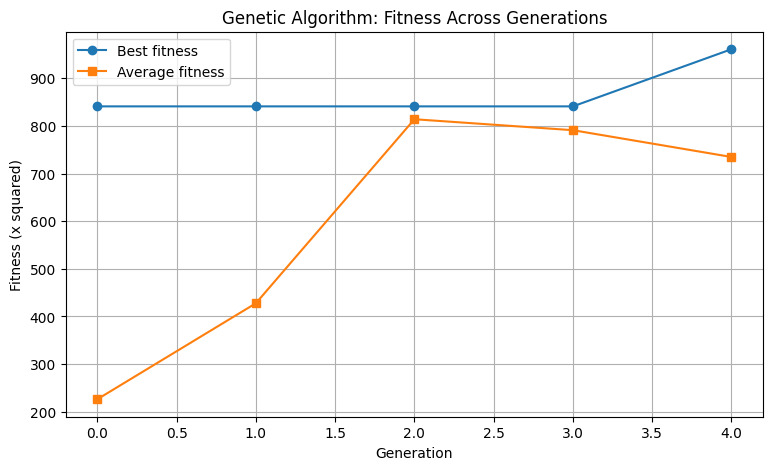

In [ ]:
generations_completed = range(len(best_history))

plt.figure(figsize=(9, 5))
plt.plot(generations_completed, best_history, marker='o', label='Best fitness')
plt.plot(generations_completed, average_history, marker='s', label='Average fitness')
plt.xlabel("Generation")
plt.ylabel("Fitness (x squared)")
plt.title("Genetic Algorithm: Fitness Across Generations")
plt.legend()
plt.grid(True)
plt.show()

## 13. Step 11 - Inspect the final solution

This cell summarizes the result and checks whether the global optimum was found. Because the GA is randomized, it may find the optimum early, or it may finish with a value below the optimum in some runs.

In [ ]:
print("Best chromosome found:", best_chromosome)
print("Decoded x:", best_x)
print("Fitness:", best_score)

if best_score >= TARGET_FITNESS:
    print(f"Success: the target fitness {TARGET_FITNESS} was reached at x = {best_x}.")
else:
    print("The target fitness was not reached in this run.")
    print("Try increasing GENERATIONS or POPULATION_SIZE, or changing the random seed.")

Best chromosome found: 11111
Decoded x: 31
Fitness: 961
Success: the target fitness 961 was reached at x = 31.


## 14. Lab exercises

Complete the following tasks in your own notebook. Write your code in the cells provided.

### Task 1 — Change the objective function
Modify the fitness function to maximize \(f(x)=x\) instead of \(f(x)=x^2\), and update `TARGET_FITNESS` to match. What solution should the algorithm seek?

### Task 2 — Change the mutation rate
Run the GA with mutation rates `0.01`, `0.05`, and `0.20`. Compare the number of generations needed to find the optimum and discuss the effect of mutation.

### Task 3 — Change the population size
Compare population sizes `4`, `8`, and `20`. Record the best final fitness for each run.

### Task 4 — Remove elitism
Modify `create_next_generation()` so it does not copy the best chromosome directly. Run the GA again and compare the best-fitness curves.

### Task 5 — Try another objective function
Use the same 5-bit chromosome representation to maximize:

\[
f(x) = 31 - |x - 19|
\]

Hint: the best solution is the value of \(x\) closest to 19. Update the fitness function and `TARGET_FITNESS`, and test whether the GA finds it.

### Task 1

Write your modified fitness function and run the algorithm.

In [ ]:
# TODO: Modify the fitness function to maximize f(x) = x.
# Keep the rest of the algorithm unchanged initially.
# Also set TARGET_FITNESS = 31 (the new maximum), since the target is no longer 31 ** 2.

### Task 2

Test different mutation rates and record the results.

Because the GA is random, a single run can be misleading: repeat each setting with several seeds (e.g., `random.seed(s)` for `s` in `range(5)`) and average the results. Use `genetic_algorithm(verbose=False)` to keep the output short.

In [ ]:
# TODO: Try mutation rates 0.01, 0.05, and 0.20.
# Record best fitness and generations needed for each run.
# Repeat each setting over several seeds and average; use verbose=False.

### Task 3

Test different population sizes.

As in Task 2, repeat each setting with several seeds and average the results, using `genetic_algorithm(verbose=False)`.

In [ ]:
# TODO: Try population sizes 4, 8, and 20.
# Record the best final fitness for each experiment.
# Repeat each setting over several seeds and average; use verbose=False.

### Task 4

Remove elitism and compare the best-fitness curves.

In [ ]:
# TODO: Modify create_next_generation() so it does not copy the best chromosome directly.
# Run the GA again and compare the best-fitness curves with and without elitism.

### Task 5

Try another objective function on the same 5-bit representation.

In [ ]:
# TODO: Update the fitness function to f(x) = 31 - |x - 19|.
# Also set TARGET_FITNESS = 31 (the new maximum), then test whether the GA finds x = 19.